# EDA : pour quels clients l'e-mail fait-il vraiment la différence ?

**Jeu** : Hillstrom (MineThatData), vraie campagne e-mail **randomisée** sur 64 000 clients : 1/3 e-mail « homme », 1/3 e-mail « femme », 1/3 sans e-mail (témoin). On observe ensuite la visite, l'achat et la dépense pendant deux semaines.

**Question** : l'effet moyen de chaque e-mail est connu (voir `reports/phase1_effets_moyens.md`). Mais est-il **le même pour tout le monde** ? Si non, cibler intelligemment rapporte plus que d'envoyer partout : c'est tout l'enjeu de l'uplift (phase 2).

Toutes les fonctions utilisées sont dans `src/ciblage/` et testées.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ciblage.causal import ate, balance, heterogeneity as het
from ciblage.data import hillstrom

df = hillstrom.load()
NAMES = {1: "E-mail homme", 2: "E-mail femme"}
COLORS = {1: "#2a78d6", 2: "#eb6834"}   # palette de référence 
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
                     "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
                     "font.size": 10})
df.head()

,recency,history,mens,womens,newbie,zip_code,channel,visit,conversion,spend,treatment
0,10,142.44,1,0,0,Surburban,Phone,0,0,0.0,2
1,6,329.08,1,1,1,Rural,Web,0,0,0.0,0
2,7,180.65,0,1,1,Surburban,Web,0,0,0.0,2
3,9,675.83,1,0,1,Rural,Web,0,0,0.0,1
4,2,45.34,1,0,0,Urban,Web,0,0,0.0,2


## 1. Qualité et composition des données

In [2]:
print(f"{len(df):,} clients | valeurs manquantes : {int(df.isna().sum().sum())}")
print("Groupes :", df["treatment"].map({0: "témoin", **NAMES}).value_counts().to_dict())
df.describe(include="all").T[["count", "mean", "min", "max"]]

64,000 clients | valeurs manquantes : 0
Groupes : {'E-mail femme': 21387, 'E-mail homme': 21307, 'témoin': 21306}


,count,mean,min,max
recency,64000.0,5.763734,1.0,12.0
history,64000.0,242.085656,29.99,3345.93
mens,64000.0,0.551031,0.0,1.0
womens,64000.0,0.549719,0.0,1.0
newbie,64000.0,0.50225,0.0,1.0
zip_code,64000,NaN,NaN,NaN
channel,64000,NaN,NaN,NaN
visit,64000.0,0.146781,0.0,1.0
conversion,64000.0,0.009031,0.0,1.0
spend,64000.0,1.050908,0.0,499.0


In [3]:
# Rareté des résultats : la visite est fréquente, l'achat rare (d'où des estimations bruitées)
df.groupby("treatment")[["visit", "conversion", "spend"]].mean().rename(index={0: "témoin", **NAMES}).round(4)

,visit,conversion,spend
treatment,,,
témoin,0.1062,0.0057,0.6528
E-mail homme,0.1828,0.0125,1.4226
E-mail femme,0.1514,0.0088,1.0772


## 2. Le tirage au sort a-t-il fonctionné ?
Si les groupes diffèrent avant la campagne, aucune comparaison ne serait causale. Critère : différence moyenne standardisée |SMD| < 0,1.

In [4]:
rep = balance.check_balance(hillstrom.encode_features(df), df["treatment"].to_numpy(), {0: 1/3, 1: 1/3, 2: 1/3})
print(f"|SMD| max = {rep.max_abs_smd:.3f}  | test des effectifs p = {rep.sample_ratio['p_value']:.2f}  | équilibré : {rep.is_balanced}")
rep.smd.round(3)

|SMD| max = 0.014  | test des effectifs p = 0.90  | équilibré : True


,smd_1,smd_2
recency,0.007,0.005
history,0.008,0.007
mens,-0.005,-0.009
womens,0.008,0.005
newbie,-0.001,0.003
zip_code_Surburban,-0.012,-0.001
zip_code_Rural,0.014,0.004
channel_Web,0.011,-0.005
channel_Multichannel,-0.004,-0.005


## 3. Effet moyen de chaque e-mail (rappel)

In [5]:
eff = ate.estimate_effects(df, outcomes=hillstrom.OUTCOMES, n_boot=1_000)
eff.assign(action=eff["treatment"].map(NAMES))[["action", "outcome", "mean_control", "ate", "ci_low", "ci_high", "lift", "p_holm"]].round(4)

,action,outcome,mean_control,ate,ci_low,ci_high,lift,p_holm
0,E-mail homme,visit,0.1062,0.0766,0.0700,0.0832,0.7214,0.0000
1,E-mail homme,conversion,0.0057,0.0068,0.0050,0.0086,1.1884,0.0000
2,E-mail homme,spend,0.6528,0.7698,0.4851,1.0545,1.1793,0.0000
3,E-mail femme,visit,0.1062,0.0452,0.0389,0.0516,0.4261,0.0000
4,E-mail femme,conversion,0.0057,0.0031,0.0015,0.0047,0.5433,0.0003
5,E-mail femme,spend,0.6528,0.4244,0.1690,0.6799,0.6502,0.0011


## 4. L'effet varie-t-il selon le profil ?
Dans un essai randomisé, le tirage au sort vaut aussi **à l'intérieur de chaque segment** : la différence de moyennes par segment estime l'effet dans ce segment. Résultat étudié : la **visite** (assez fréquente pour des estimations stables). Intervalles de confiance de Welch à 95 %.

In [6]:
df["a_achete"] = np.select([(df.mens == 1) & (df.womens == 1), df.mens == 1], ["homme et femme", "homme seulement"], "femme seulement")
df["recence"] = pd.cut(df["recency"], [0, 3, 6, 9, 12], labels=["1-3 mois", "4-6 mois", "7-9 mois", "10-12 mois"])
df["historique"] = het.bin_quantiles(df["history"], label="Q")
df["nouveau"] = df["newbie"].map({0: "non", 1: "oui"})
SEGMENTS = {"a_achete": "A déjà acheté (rayon)", "nouveau": "Nouveau client", "channel": "Canal d'achat",
            "zip_code": "Zone", "recence": "Dernier achat", "historique": "Dépenses passées (quartile)"}
res = pd.concat([het.uplift_by_segment(df, s, "visit") for s in SEGMENTS], ignore_index=True)
res.assign(action=res["treatment"].map(NAMES), uplift_pts=(100 * res["uplift"]).round(1))[
    ["segment", "niveau", "action", "n_traite", "taux_temoin", "uplift_pts", "ci_low", "ci_high", "p_holm"]].round(4)

,segment,niveau,action,n_traite,taux_temoin,uplift_pts,ci_low,ci_high,p_holm
0,a_achete,femme seulement,E-mail homme,9568,0.0958,7.1,0.0611,0.0801,0.0000
1,a_achete,femme seulement,E-mail femme,9647,0.0958,7.4,0.0644,0.0835,0.0000
2,a_achete,homme et femme,E-mail homme,2181,0.1805,13.4,0.1090,0.1598,0.0000
3,a_achete,homme et femme,E-mail femme,2118,0.1805,7.1,0.0465,0.0957,0.0000
4,a_achete,homme seulement,E-mail homme,9558,0.0998,6.9,0.0595,0.0788,0.0000
5,a_achete,homme seulement,E-mail femme,9622,0.0998,1.1,0.0024,0.0197,0.0123
6,nouveau,non,E-mail homme,10621,0.1337,7.8,0.0677,0.0879,0.0000
7,nouveau,non,E-mail femme,10624,0.1337,4.0,0.0304,0.0498,0.0000
8,nouveau,oui,E-mail homme,10686,0.0788,7.5,0.0668,0.0838,0.0000
9,nouveau,oui,E-mail femme,10763,0.0788,5.0,0.0423,0.0586,0.0000


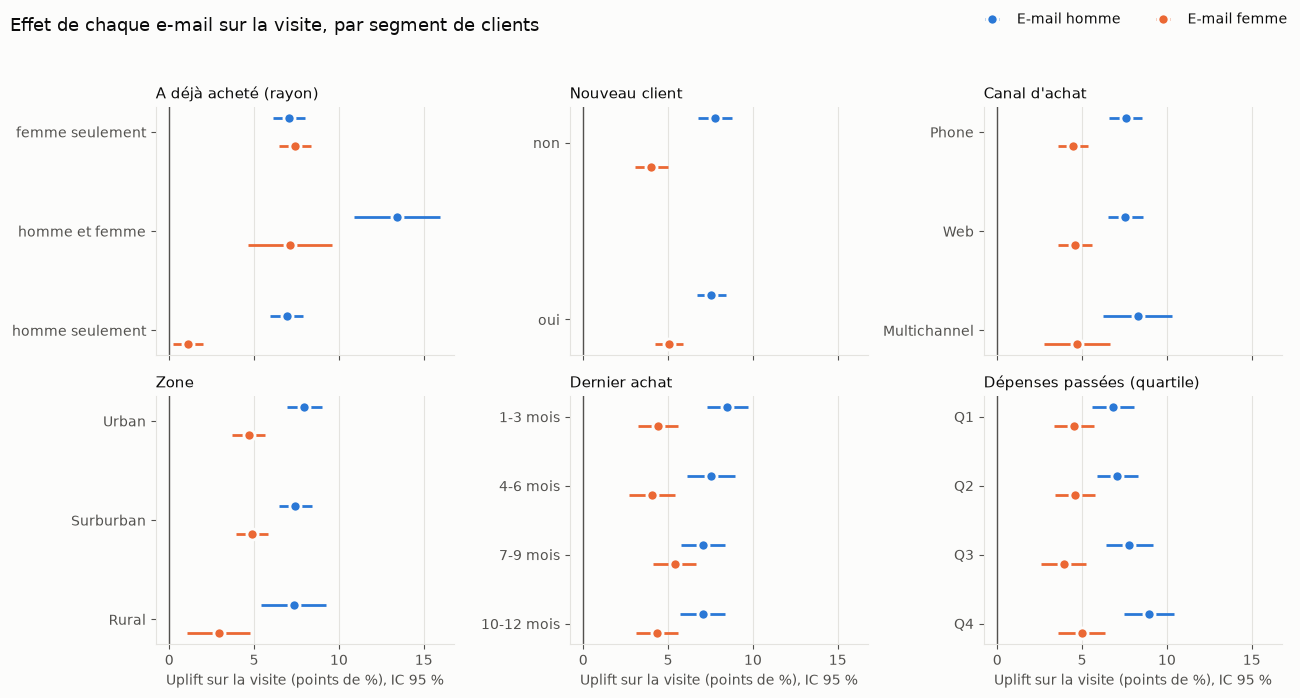

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharex=True)
for ax, (seg, title) in zip(axes.flat, SEGMENTS.items()):
    part = res[res["segment"] == seg]
    levels = list(dict.fromkeys(part["niveau"]))
    y = np.arange(len(levels))
    for k, g in enumerate((1, 2)):
        p = part[part["treatment"] == g].set_index("niveau").reindex(levels)
        yy = y + (k - 0.5) * 0.28
        ax.errorbar(100 * p["uplift"], yy, xerr=[100 * (p["uplift"] - p["ci_low"]), 100 * (p["ci_high"] - p["uplift"])],
                    fmt="o", ms=8, color=COLORS[g], ecolor=COLORS[g], elinewidth=2, capsize=0,
                    markeredgecolor=SURFACE, markeredgewidth=2, label=NAMES[g])
    ax.set_yticks(y, [str(l) for l in levels])
    ax.invert_yaxis()
    ax.axvline(0, color=INK_2, lw=1)
    ax.grid(axis="x", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.set_title(title, loc="left", fontsize=11, color=INK)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
for ax in axes[-1]:
    ax.set_xlabel("Uplift sur la visite (points de %), IC 95 %")
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncol=2, frameon=False)
fig.suptitle("Effet de chaque e-mail sur la visite, par segment de clients", x=0.01, ha="left", fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

## 5. Quel e-mail envoyer à quel profil ?

In [8]:
best = (res[res["segment"] == "a_achete"].pivot(index="niveau", columns="treatment", values="uplift") * 100).round(1)
best.columns = [NAMES[c] for c in best.columns]
best["meilleur e-mail"] = best.idxmax(axis=1)
best["écart (pts)"] = (best[NAMES[1]] - best[NAMES[2]]).abs().round(1)
best

,E-mail homme,E-mail femme,meilleur e-mail,écart (pts)
niveau,,,,
femme seulement,7.1,7.4,E-mail femme,0.3
homme et femme,13.4,7.1,E-mail homme,6.3
homme seulement,6.9,1.1,E-mail homme,5.8


In [9]:
# Les achats et la dépense : même lecture, mais beaucoup plus bruitée (achats rares)
conv = het.uplift_by_segment(df, "a_achete", "spend")
conv.assign(action=conv["treatment"].map(NAMES))[["niveau", "action", "uplift", "ci_low", "ci_high", "p_holm"]].round(3)

,niveau,action,uplift,ci_low,ci_high,p_holm
0,femme seulement,E-mail homme,0.616,0.270,0.962,0.002
1,femme seulement,E-mail femme,0.632,0.295,0.968,0.001
2,homme et femme,E-mail homme,1.825,0.490,3.160,0.022
3,homme et femme,E-mail femme,0.162,-0.814,1.137,0.745
4,homme seulement,E-mail homme,0.683,0.247,1.118,0.009
5,homme seulement,E-mail femme,0.278,-0.124,0.680,0.349


## 6. Ce qu'il faut retenir

1. **Le tirage au sort est réussi** : |SMD| ≤ 0,014 sur toutes les variables, effectifs conformes au 1/3-1/3-1/3. Les comparaisons sont causales.
2. **Les deux e-mails augmentent les visites**, mais pas autant : en moyenne +7,7 points pour l'e-mail homme, +4,5 pour l'e-mail femme (sur une base de 10,6 %).
3. **L'effet dépend fortement de ce que le client a déjà acheté**, et c'est la principale source d'hétérogénéité :
   - clients **« homme seulement »** : l'e-mail femme ne fait presque rien (+1,1 point), l'e-mail homme fait +6,9 ;
   - clients **« femme seulement »** : les deux e-mails se valent (+7,1 et +7,4). On peut donc choisir **le moins cher** ;
   - clients **« homme et femme »** : l'e-mail homme fait +13,4 points, presque le double de l'e-mail femme.
4. **Les autres variables** (nouveau client, canal, zone, récence, dépenses passées) changent peu l'effet. Il y a seulement une légère tendance à un effet plus fort chez les gros acheteurs (Q4) pour l'e-mail homme.
5. **L'achat et la dépense** suivent la même logique, mais sont beaucoup plus bruités (achats rares, environ 1 %). C'est pour cette raison que la **visite** sera la cible principale des modèles d'uplift.

**Conséquence pour la suite** : envoyer le même e-mail à tout le monde gaspille du budget, car l'e-mail femme est presque inutile pour un tiers des clients. La phase 2 va estimer l'uplift **client par client**, en combinant toutes les variables plutôt qu'en regardant un segment à la fois, puis la phase 3 décidera qui reçoit quoi sous un budget donné.

*Limites* : une seule campagne (2008), sur deux semaines ; les segments sont choisis à la main et regardés un par un (p-valeurs corrigées par Holm à l'intérieur de chaque segment, pas sur l'ensemble des segments).